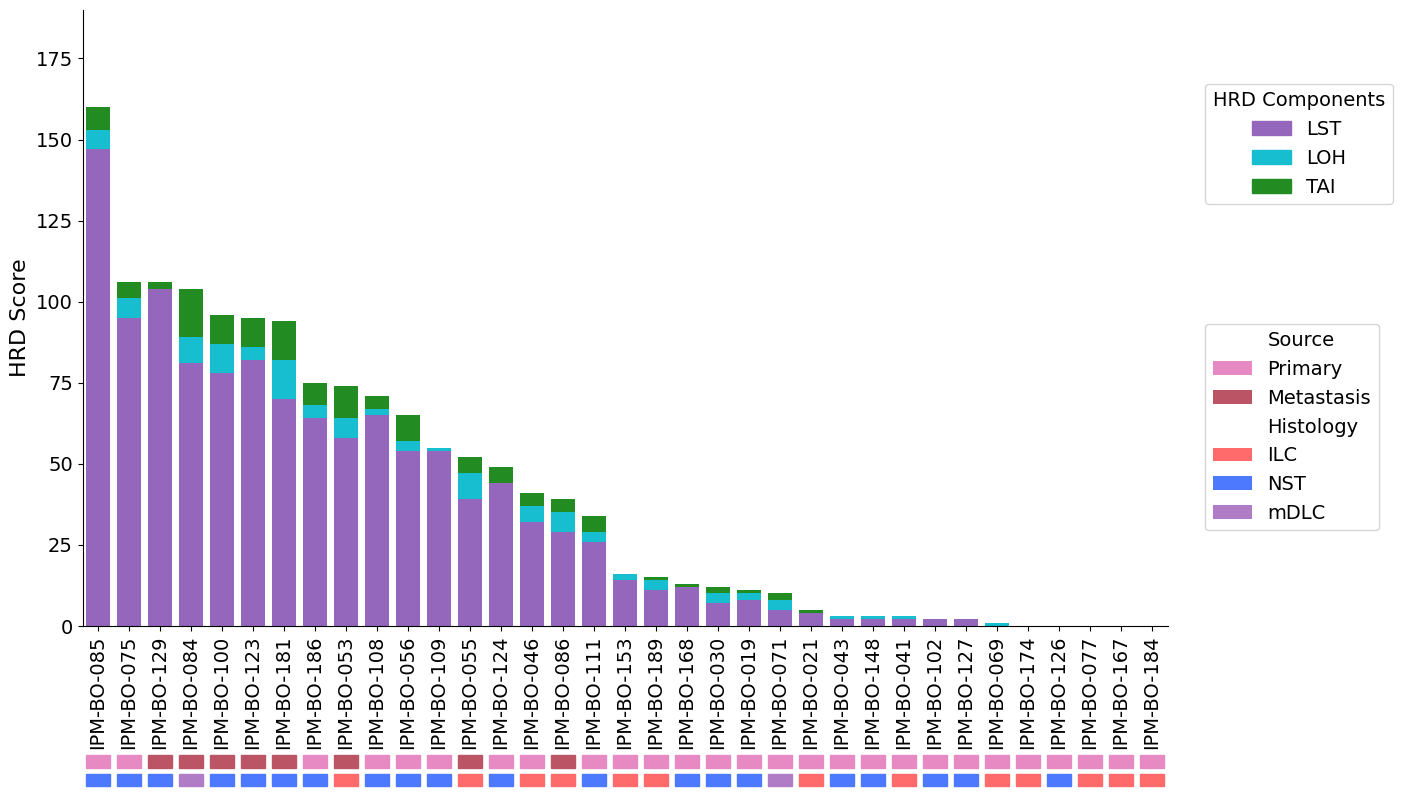

Plot saved at: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot/IPM_ALL_HRD_Stacked_Bar_Plot_Annotated.png
Plot saved at: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot/IPM_ALL_HRD_Stacked_Bar_Plot_Annotated.pdf


In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# =============================
# Global font size and style
# =============================
plt.rcParams.update({
    "font.family": "DejaVu Sans", 
    "axes.labelsize": 16,         
    "xtick.labelsize": 14,        
    "ytick.labelsize": 14,        
    "legend.fontsize": 14,        
    "legend.title_fontsize": 14
})

# Load the data
df = pd.read_csv("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/IPM-BO_HRD.csv")

# Sort samples by HRD total score for better visual consistency
df = df.sort_values("Total", ascending=False).reset_index(drop=True)

# Create color maps for Source and Histology
source_colors = {
    "Metastasis": "#BB5566",
    "Primary": "#E78AC3"
}

histology_colors = {"ILC": "#FF6B6B", "NST": "#4D79FF", "mDLC": "#B07CC6"}

# Create the figure and axis
fig, ax = plt.subplots(figsize=(14, 8))

# Define unique, unused colors for LST and LOH
color_lst = "#9467bd"   # Purple
color_loh = "#17becf"   # Orange
color_tai = "#228B22"   # Forest Green

# Plot stacked bars
ax.bar(df["Sample"], df["LST"], color=color_lst, label='LST')
ax.bar(df["Sample"], df["LOH"], bottom=df["LST"], color=color_loh, label='LOH')
ax.bar(df["Sample"], df["TAI"], bottom=df["LST"] + df["LOH"], color=color_tai, label='TAI')

# Set Y-axis limit
ax.set_ylim(0, 190)

# Set X-axis labels
ax.set_xticks(range(len(df["Sample"])))
ax.set_xticklabels(df["Sample"], rotation=90, ha='center')
ax.set_xlim(-0.5, len(df["Sample"]) - 0.5)
ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True)

# Add annotation bars *just below* the sample labels using Axes coordinates
bar_width = 0.8
bar_height = 0.02  # small height in axes fraction
for i, sample in enumerate(df["Sample"]):
    source = df.loc[i, "Source"]
    hist = df.loc[i, "Histology"]

    x = i - bar_width / 2

    ax.add_patch(plt.Rectangle(
        (x, -0.23), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=source_colors.get(source, "#cccccc"),
        clip_on=False
    ))

    ax.add_patch(plt.Rectangle(
        (x, -0.26), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=histology_colors.get(hist, "#888888"),
        clip_on=False
    ))

# Remove top and right spines (clean plot frame)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

# Axis label
ax.set_ylabel("HRD Score")

# --- Build grouped legend ---
legend_elements = []
legend_group_titles = {
    "Source": df["Source"].dropna().unique(),
    "Histology": ["ILC", "NST", "mDLC"]
}
for group_name, items in legend_group_titles.items():
    legend_elements.append(Patch(facecolor='white', edgecolor='white', label=group_name))
    for item in items:
        color = source_colors.get(item) if group_name == "Source" else histology_colors.get(item, "#cccccc")
        legend_elements.append(Patch(facecolor=color, label=item))

# Custom legend for main HRD components and cutoff line
hrd_legend = [
    Patch(color=color_lst, label="LST"),
    Patch(color=color_loh, label="LOH"),
    Patch(color=color_tai, label="TAI"),
]

# Place legends using fig.legend to avoid overwriting
fig.legend(handles=hrd_legend, loc='upper left', bbox_to_anchor=(0.92, 0.8), title="HRD Components")
fig.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(0.92, 0.5), frameon=True, title_fontsize=14)

# Save the final plot
save_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot"
os.makedirs(save_path, exist_ok=True)

png_file = os.path.join(save_path, "IPM_ALL_HRD_Stacked_Bar_Plot_Annotated.png")
pdf_file = os.path.join(save_path, "IPM_ALL_HRD_Stacked_Bar_Plot_Annotated.pdf")

plt.savefig(png_file, dpi=300, bbox_inches='tight')
plt.savefig(pdf_file, bbox_inches='tight')

plt.show()

print(f"Plot saved at: {png_file}")
print(f"Plot saved at: {pdf_file}")

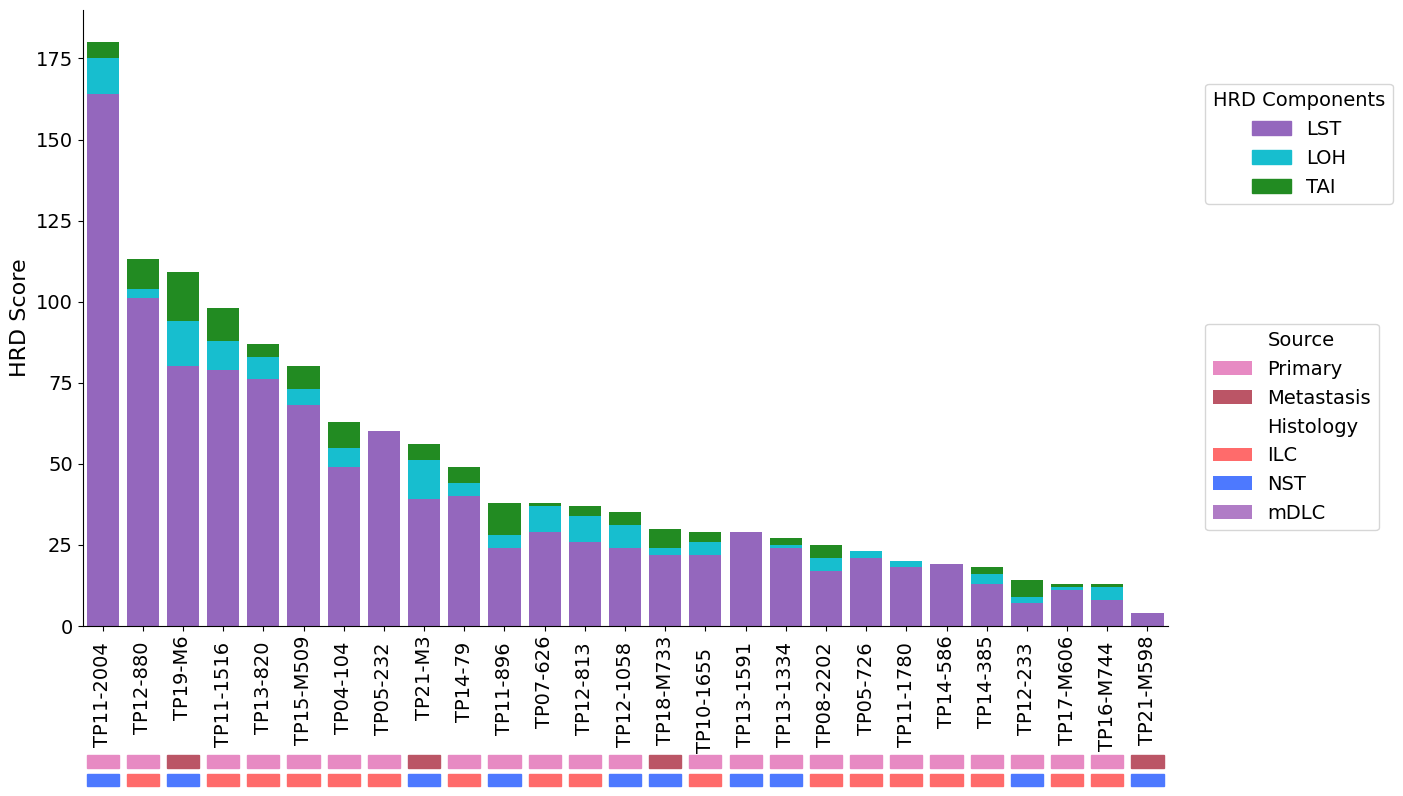

Plot saved at: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot/Tumor_ALL_HRD_Stacked_Bar_Plot_Annotated.png
Plot saved at: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot/Tumor_ALL_HRD_Stacked_Bar_Plot_Annotated.pdf


In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# =============================
# Global font size and style
# =============================
plt.rcParams.update({
    "font.family": "DejaVu Sans", 
    "axes.labelsize": 16,         
    "xtick.labelsize": 14,        
    "ytick.labelsize": 14,        
    "legend.fontsize": 14,        
    "legend.title_fontsize": 14
})

# Load the data
df = pd.read_csv("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Tumor_HRD.csv")

# Sort samples by HRD total score for better visual consistency
df = df.sort_values("Total", ascending=False).reset_index(drop=True)

# Create color maps for Source and Histology
source_colors = {
    "Metastasis": "#BB5566",
    "Primary": "#E78AC3"
}

histology_colors = {"ILC": "#FF6B6B", "NST": "#4D79FF", "mDLC": "#B07CC6"}

# Create the figure and axis
fig, ax = plt.subplots(figsize=(14, 8))

# Define unique, unused colors for LST and LOH
color_lst = "#9467bd"   # Purple
color_loh = "#17becf"   # Orange
color_tai = "#228B22"   # Forest Green

# Plot stacked bars
ax.bar(df["Sample"], df["LST"], color=color_lst, label='LST')
ax.bar(df["Sample"], df["LOH"], bottom=df["LST"], color=color_loh, label='LOH')
ax.bar(df["Sample"], df["TAI"], bottom=df["LST"] + df["LOH"], color=color_tai, label='TAI')

# Set Y-axis limit
ax.set_ylim(0, 190)

# Set X-axis labels
ax.set_xticks(range(len(df["Sample"])))
ax.set_xticklabels(df["Sample"], rotation=90, ha='center')
ax.set_xlim(-0.5, len(df["Sample"]) - 0.5)
ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True)

# Add annotation bars *just below* the sample labels using Axes coordinates
bar_width = 0.8
bar_height = 0.02  # small height in axes fraction
for i, sample in enumerate(df["Sample"]):
    source = df.loc[i, "Source"]
    hist = df.loc[i, "Histology"]

    x = i - bar_width / 2

    ax.add_patch(plt.Rectangle(
        (x, -0.23), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=source_colors.get(source, "#cccccc"),
        clip_on=False
    ))

    ax.add_patch(plt.Rectangle(
        (x, -0.26), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=histology_colors.get(hist, "#888888"),
        clip_on=False
    ))

# Remove top and right spines (clean plot frame)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

# Axis label
ax.set_ylabel("HRD Score")

# --- Build grouped legend ---
legend_elements = []
legend_group_titles = {
    "Source": df["Source"].dropna().unique(),
    "Histology": ["ILC", "NST", "mDLC"]
}
for group_name, items in legend_group_titles.items():
    legend_elements.append(Patch(facecolor='white', edgecolor='white', label=group_name))
    for item in items:
        color = source_colors.get(item) if group_name == "Source" else histology_colors.get(item, "#cccccc")
        legend_elements.append(Patch(facecolor=color, label=item))

# Custom legend for main HRD components and cutoff line
hrd_legend = [
    Patch(color=color_lst, label="LST"),
    Patch(color=color_loh, label="LOH"),
    Patch(color=color_tai, label="TAI"),
]

# Place legends using fig.legend to avoid overwriting
fig.legend(handles=hrd_legend, loc='upper left', bbox_to_anchor=(0.92, 0.8), title="HRD Components")
fig.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(0.92, 0.5), frameon=True, title_fontsize=14)

# Save the final plot
save_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot"
os.makedirs(save_path, exist_ok=True)

png_file = os.path.join(save_path, "Tumor_ALL_HRD_Stacked_Bar_Plot_Annotated.png")
pdf_file = os.path.join(save_path, "Tumor_ALL_HRD_Stacked_Bar_Plot_Annotated.pdf")

plt.savefig(png_file, dpi=300, bbox_inches='tight')
plt.savefig(pdf_file, bbox_inches='tight')

plt.show()

print(f"Plot saved at: {png_file}")
print(f"Plot saved at: {pdf_file}")

Samples with BFB + amplicons:
BFB -    211
BFB +      5
Name: BFB Class, dtype: int64
['IPM-BO-108' 'IPM-BO-123' 'IPM-BO-186' 'IPM-BO-53']


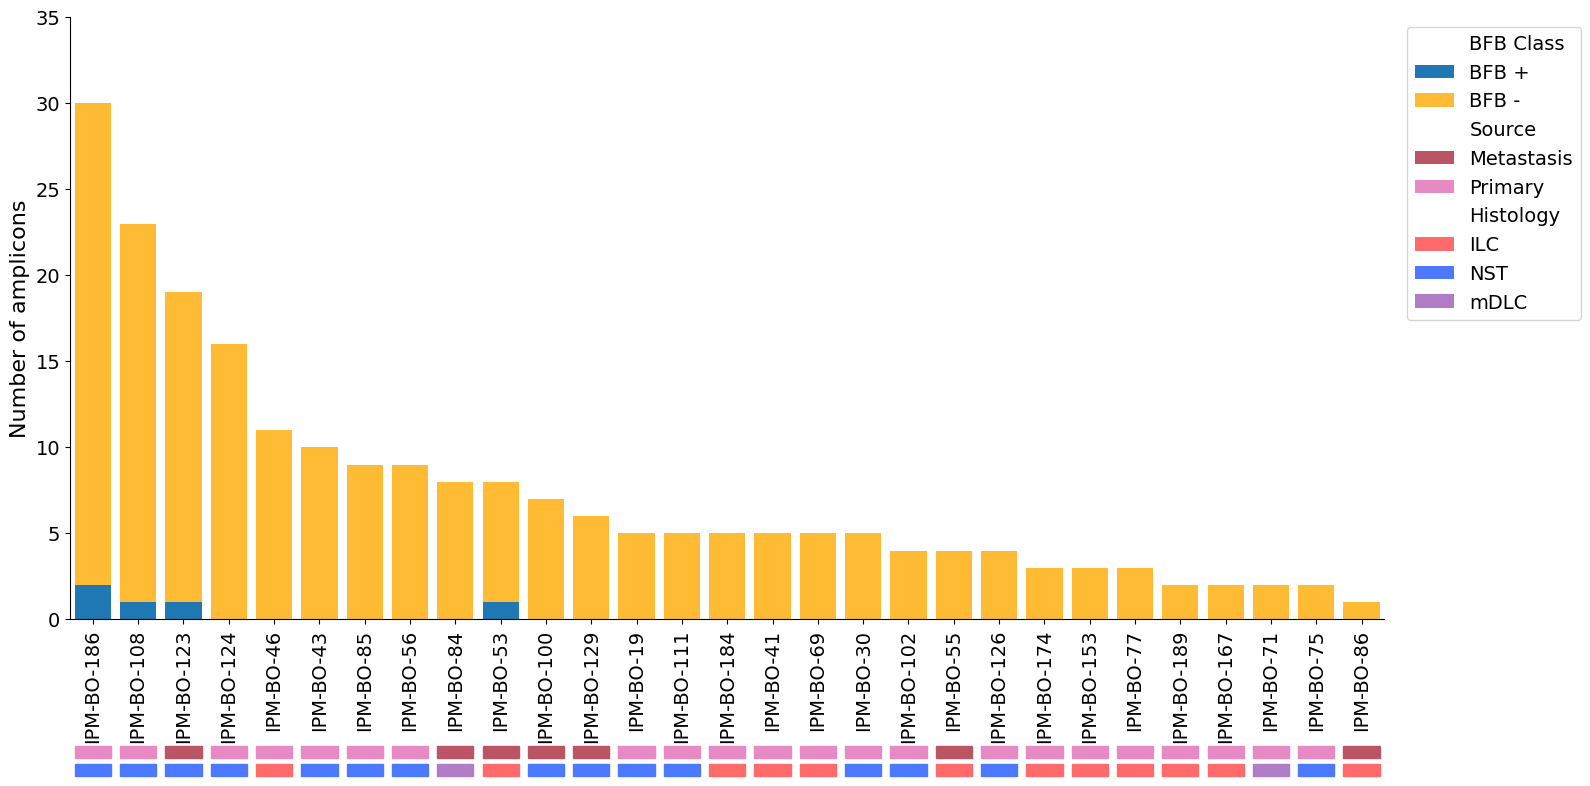

 Amplicon_counts_per_sample_annotated_bars_IPM saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Amplicon_counts_per_sample_annotated_bars_IPM.pdf


In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import os

# === Load dataset ===
csv_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Combined_BFB_summary_by_sample_amplicon_IPM.csv"
df = pd.read_csv(csv_path)
output_dir = os.path.dirname(csv_path)

plt.rcParams.update({
    "font.family": "DejaVu Sans",  
    "axes.labelsize": 16,         # Axis label font
    "xtick.labelsize": 14,        # X-tick font
    "ytick.labelsize": 14,        # Y-tick font
    "legend.fontsize": 14,        # Legend text font
    "legend.title_fontsize": 14   # Legend title font
})

# === Clean and classify BFB status ===
df['Final Score'] = pd.to_numeric(df['Final Score'], errors='coerce')
df['BFB Class'] = df['Final Score'].apply(lambda x: 'BFB +' if x < 1.8 else 'BFB -')

# Filter rows with BFB +
bfb_positive_df = df[df['BFB Class'] == 'BFB +']
bfb_positive_samples = bfb_positive_df['Sample ID'].unique()

print("Samples with BFB + amplicons:")
print(df['BFB Class'].value_counts())
print(bfb_positive_samples)

# === Color maps ===
source_colors = {
    "Metastasis": "#BB5566",
    "Primary": "#E78AC3"
}

histology_colors = {"ILC": "#FF6B6B", "NST": "#4D79FF", "mDLC": "#B07CC6"}

# === Compute BFB counts for sorting ===
count_df = df['Sample ID'].value_counts().reset_index()
count_df.columns = ['Sample ID', 'BFB Count']

# === Merge metadata for annotations ===
metadata_df = df[['Sample ID', 'Source', 'Histology']].drop_duplicates()
count_df = count_df.merge(metadata_df, on='Sample ID', how='left')
count_df = count_df.sort_values(by='BFB Count', ascending=False).reset_index(drop=True)

# === Prepare stacked BFB class counts per sample ===
stacked_df = df.groupby(['Sample ID', 'BFB Class']).size().unstack(fill_value=0)
stacked_df = stacked_df.loc[count_df['Sample ID']]  # match sample order

# === Plot setup ===
fig, ax = plt.subplots(figsize=(16, 8))

bar_colors = {
    'BFB +': '#1f77b4',  # Blue
    'BFB -': '#ffbb33'   # Orange/Yellow
}

bottom = None
for cls in ['BFB +', 'BFB -']:
    ax.bar(
        stacked_df.index,
        stacked_df[cls],
        bottom=bottom,
        label=cls,
        color=bar_colors[cls]
    )
    bottom = stacked_df[cls] if bottom is None else bottom + stacked_df[cls]
    
# === Title and axis ===
ax.set_ylabel("Number of amplicons", fontsize=16)
# Set X-axis tick positions and labels
ax.set_xticks(range(len(count_df)))  # positions: 0, 1, 2, ...
ax.set_xticklabels(count_df["Sample ID"], rotation=90, ha='center')  # labels: sample IDs

# Hide all X-axis ticks and labels (keep axis for annotation bars)
ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True)
ax.tick_params(axis='y', labelsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# === Add annotation bands under bars ===
bar_width = 0.8
bar_height = 0.02

for i, row in count_df.iterrows():
    source = row["Source"]
    hist = row["Histology"]
    x = i - bar_width / 2

    # Source band
    ax.add_patch(plt.Rectangle(
        (x, -0.23), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=source_colors.get(source, '#CCCCCC'),
        clip_on=False
    ))

    # Histology band
    ax.add_patch(plt.Rectangle(
        (x, -0.26), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=histology_colors.get(hist, '#888888'),
        clip_on=False
    ))

# === Legend setup ===
legend_elements = [
    Patch(facecolor='white', edgecolor='white', label='BFB Class'),
    Patch(facecolor=bar_colors['BFB +'], label='BFB +'),
    Patch(facecolor=bar_colors['BFB -'], label='BFB -'),
    Patch(facecolor='white', edgecolor='white', label='Source'),
] + [Patch(facecolor=color, label=label) for label, color in source_colors.items()] + [
    Patch(facecolor='white', edgecolor='white', label='Histology')
] + [Patch(facecolor=color, label=label) for label, color in histology_colors.items()]

ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.01, 1))

# === Finalize ===
ax.set_xlim(-0.5, len(stacked_df) - 0.5)
ax.set_ylim(0, 35)
plt.tight_layout()
output_path = os.path.join(output_dir, "Amplicon_counts_per_sample_annotated_bars_IPM.pdf")
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()

print(f" Amplicon_counts_per_sample_annotated_bars_IPM saved to: {output_path}")


Samples with BFB + amplicons:
BFB -    129
BFB +      2
Name: BFB Class, dtype: int64
['TP18-M733' 'TP19-M6']


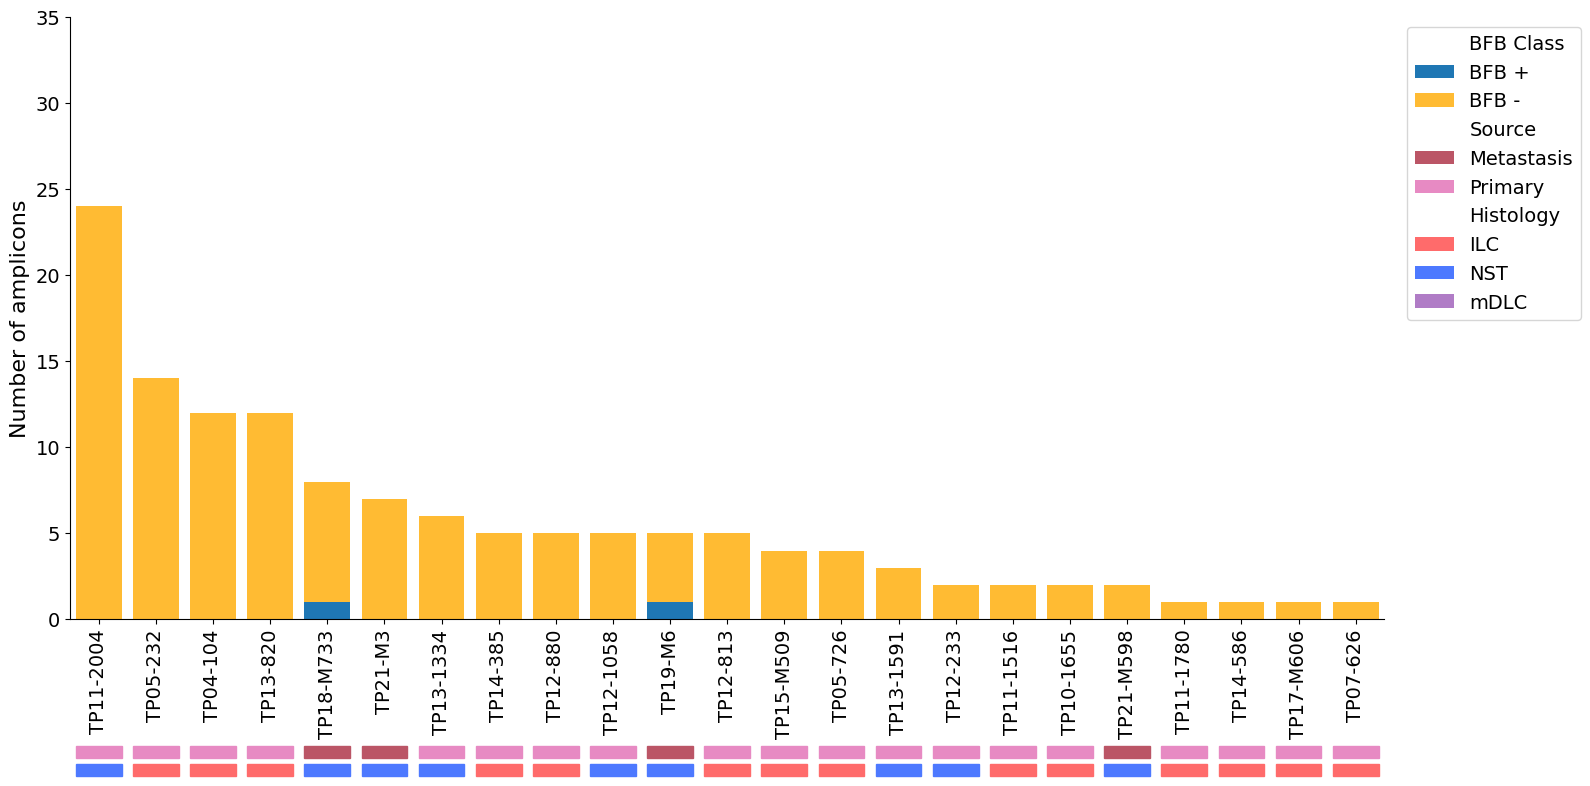

✅ Amplicon_counts_per_sample plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Amplicon_counts_per_sample_annotated_bars_Tumor.pdf


In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import os

# === Load dataset ===
csv_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/BFBCycle/Output/Combined_BFB_summary_by_sample_amplicon_Tumor.csv"
df = pd.read_csv(csv_path)
output_dir = os.path.dirname(csv_path)

plt.rcParams.update({
    "font.family": "DejaVu Sans",   # or 'Arial', 'Times New Roman'
    "axes.labelsize": 16,         # Axis label font
    "xtick.labelsize": 14,        # X-tick font
    "ytick.labelsize": 14,        # Y-tick font
    "legend.fontsize": 14,        # Legend text font
    "legend.title_fontsize": 14   # Legend title font
})

# === Clean and classify BFB status ===
df['Final Score'] = pd.to_numeric(df['Final Score'], errors='coerce')  # handle invalid values safely
df['BFB Class'] = df['Final Score'].apply(lambda x: 'BFB +' if x < 1.8 else 'BFB -')

# Filter rows with BFB +
bfb_positive_df = df[df['BFB Class'] == 'BFB +']
bfb_positive_samples = bfb_positive_df['Sample ID'].unique()

print("Samples with BFB + amplicons:")
print(df['BFB Class'].value_counts())
print(bfb_positive_samples)

# === Color maps ===
source_colors = {
    "Metastasis": "#BB5566",
    "Primary": "#E78AC3"
}

histology_colors = {"ILC": "#FF6B6B", "NST": "#4D79FF", "mDLC": "#B07CC6"}

# === Compute BFB counts ===
count_df = df['Sample ID'].value_counts().reset_index()
count_df.columns = ['Sample ID', 'BFB Count']

# === Merge metadata ===
metadata_df = df[['Sample ID', 'Source', 'Histology']].drop_duplicates()
count_df = count_df.merge(metadata_df, on='Sample ID', how='left')
count_df = count_df.sort_values(by='BFB Count', ascending=False).reset_index(drop=True)

# === Prepare data for stacked bar plot ===
stacked_df = df.groupby(['Sample ID', 'BFB Class']).size().unstack(fill_value=0)
stacked_df = stacked_df.loc[count_df['Sample ID']]  # preserve sample order

# === Plot setup ===
fig, ax = plt.subplots(figsize=(16, 8))

# Bar colors
bar_colors = {
    'BFB +': '#1f77b4',  # Blue
    'BFB -': '#ffbb33'   # Orange/Yellow
}

# Plot stacked bars
bottom = None
for cls in ['BFB +', 'BFB -']:
    ax.bar(
        stacked_df.index,
        stacked_df[cls],
        bottom=bottom,
        label=cls,
        color=bar_colors[cls]
    )
    bottom = stacked_df[cls] if bottom is None else bottom + stacked_df[cls]

# === Title and axis ===
ax.set_ylabel("Number of amplicons", fontsize=16)
# Set X-axis tick positions and labels
ax.set_xticks(range(len(count_df)))  # positions: 0, 1, 2, ...
ax.set_xticklabels(count_df["Sample ID"], rotation=90, ha='center')  # labels: sample IDs


# Hide all X-axis ticks and labels (keep axis for annotation bars)
ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True)
ax.tick_params(axis='y', labelsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# === Add stacked annotation bars ===
bar_width = 0.8
bar_height = 0.02

for i, row in count_df.iterrows():
    # Source (top band)
    ax.add_patch(plt.Rectangle(
        (i - bar_width / 2, -0.23), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=source_colors.get(row['Source'], '#CCCCCC'),
        clip_on=False
    ))
    # Histology (bottom band)
    ax.add_patch(plt.Rectangle(
        (i - bar_width / 2, -0.26), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=histology_colors.get(row['Histology'], '#888888'),
        clip_on=False
    ))

# === Legend ===
legend_elements = []

# BFB Class Group
legend_elements.append(Patch(facecolor='white', edgecolor='white', label='BFB Class'))
for label, color in bar_colors.items():
    legend_elements.append(Patch(facecolor=color, label=label))

# Source Group
legend_elements.append(Patch(facecolor='white', edgecolor='white', label='Source'))
for label, color in source_colors.items():
    legend_elements.append(Patch(facecolor=color, label=label))

# Histology Group
legend_elements.append(Patch(facecolor='white', edgecolor='white', label='Histology'))
for label, color in histology_colors.items():
    legend_elements.append(Patch(facecolor=color, label=label))

ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.01, 1))

# === Adjust layout ===
ax.set_xlim(-0.5, len(stacked_df) - 0.5)
ax.set_ylim(0, 35)
plt.tight_layout()
output_path = os.path.join(output_dir, "Amplicon_counts_per_sample_annotated_bars_Tumor.pdf")
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Amplicon_counts_per_sample plot saved to: {output_path}")


Total number of rows: 35
Number of unique samples: 35

Correlation matrix:
                     Del       Dup       Ins       Inv  Transloc-Inter  \
Del             1.000000  0.436255  0.225130  0.427728        0.601240   
Dup             0.436255  1.000000  0.227002  0.554598        0.743247   
Ins             0.225130  0.227002  1.000000  0.072869        0.384516   
Inv             0.427728  0.554598  0.072869  1.000000        0.678622   
Transloc-Inter  0.601240  0.743247  0.384516  0.678622        1.000000   
Transloc-Intra  0.292373  0.229905  0.017909  0.821689        0.389296   
Total           0.702487  0.619409  0.447640  0.836561        0.806267   
HRD Score       0.680878  0.511138  0.531312  0.448434        0.798867   

                Transloc-Intra     Total  HRD Score  
Del                   0.292373  0.702487   0.680878  
Dup                   0.229905  0.619409   0.511138  
Ins                   0.017909  0.447640   0.531312  
Inv                   0.821689  0.836561  

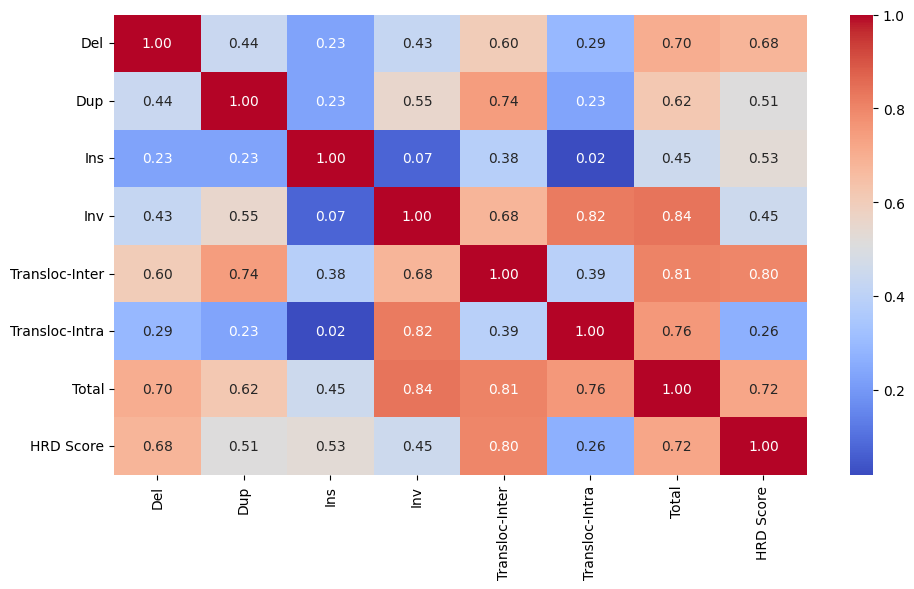

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# === Load  CSV ===
csv_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_SV_HRD_IPM.csv"
df = pd.read_csv(csv_path, sep=None, engine="python")  # auto-detect delimiter

# === Clean column names ===
df.columns = df.columns.str.strip()

# === Print sample count ===
print("Total number of rows:", len(df))

if "sample" in df.columns:
    print("Number of unique samples:", df["sample"].nunique())
else:
    print("Column 'sample' not found.")

# === Ensure HRD Score is numeric ===
df["HRD Score"] = pd.to_numeric(df["HRD Score"], errors="coerce")

# === Select features for correlation ===
features = ["Del", "Dup", "Ins", "Inv", "Transloc-Inter", "Transloc-Intra", "Total", "HRD Score"]

# Check missing columns
missing = [col for col in features if col not in df.columns]
if missing:
    raise ValueError(f"Missing columns in input file: {missing}")

# === Compute correlation matrix ===
correlation_matrix = df[features].corr()

# Print correlation matrix
print("\nCorrelation matrix:")
print(correlation_matrix)

# === Plot and save heatmap ===
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
# plt.title("Correlation of SV Types with HRD Score", fontsize=14, fontweight="bold")
plt.tight_layout()

# Save plot
output_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_SV_HRD_IPM_correlation_heatmap.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

Total number of rows: 27
Number of unique samples: 27

Correlation matrix:
                     Del       Dup       Ins       Inv  Transloc-Inter  \
Del             1.000000  0.622134  0.614707  0.783471        0.747715   
Dup             0.622134  1.000000  0.869931  0.579124        0.548357   
Ins             0.614707  0.869931  1.000000  0.391633        0.353979   
Inv             0.783471  0.579124  0.391633  1.000000        0.961987   
Transloc-Inter  0.747715  0.548357  0.353979  0.961987        1.000000   
Transloc-Intra  0.703124  0.527073  0.343057  0.866087        0.810635   
Total           0.886159  0.721619  0.577316  0.957168        0.943702   
HRD Score       0.641769  0.487457  0.324770  0.714581        0.714170   

                Transloc-Intra     Total  HRD Score  
Del                   0.703124  0.886159   0.641769  
Dup                   0.527073  0.721619   0.487457  
Ins                   0.343057  0.577316   0.324770  
Inv                   0.866087  0.957168  

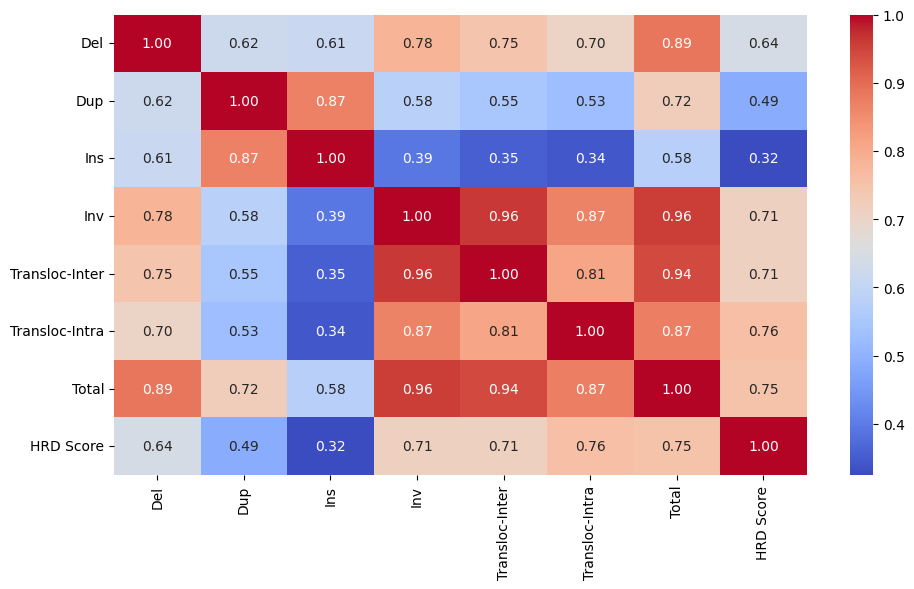

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# === Load  CSV ===
csv_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_SV_HRD_Tumor.csv"
df = pd.read_csv(csv_path, sep=None, engine="python")  # auto-detect delimiter

# === Clean column names ===
df.columns = df.columns.str.strip()

# === Print sample count ===
print("Total number of rows:", len(df))

if "sample" in df.columns:
    print("Number of unique samples:", df["sample"].nunique())
else:
    print("Column 'sample' not found.")

# === Ensure HRD Score is numeric ===
df["HRD Score"] = pd.to_numeric(df["HRD Score"], errors="coerce")

# === Select features for correlation ===
features = ["Del", "Dup", "Ins", "Inv", "Transloc-Inter", "Transloc-Intra", "Total", "HRD Score"]

# Check missing columns
missing = [col for col in features if col not in df.columns]
if missing:
    raise ValueError(f"Missing columns in input file: {missing}")

# === Compute correlation matrix ===
correlation_matrix = df[features].corr()

# Print correlation matrix
print("\nCorrelation matrix:")
print(correlation_matrix)

# === Plot and save heatmap ===
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
# plt.title("Correlation of SV Types with HRD Score", fontsize=14, fontweight="bold")
plt.tight_layout()

# Save plot
output_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_SV_HRD_Tumor_correlation_heatmap.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()